# 5.6 Implementación computacional del análisis de movimiento de peces

**Curso:** Procesamiento Digital de Señales · USIL · Equipo 2  
**Objetivo de este avance:** convertir trayectorias CVAT de referencia en señales,
remuestrearlas, aplicar un FIR de cinco muestras y comparar movimiento y espectros.

Se emplea la secuencia **Ancona** del dataset DIGI4ECO. Las cajas y los IDs proceden
del XML del dataset: **este notebook no detecta peces automáticamente**. No entrena
YOLO ni calcula precisión de un detector, ni clasifica actividad o tamaño.

**Cómo ejecutar:** en VS Code seleccionar el kernel `.venv`; en Google Colab subir
este `.ipynb` mediante *Archivo → Subir notebook*, ejecutar en orden y, cuando se
solicite, seleccionar `video.mp4` y `annotations.xml` de la carpeta **Ancona**.
El notebook contiene los módulos Python necesarios; no necesita descargar código
de un repositorio. La validación entregada corresponde a ejecución local en macOS.


## 1 Preparación del entorno

Se comprueban las bibliotecas necesarias. Si alguna falta, se instala en el kernel
actual. Las versiones utilizadas quedan registradas en el resumen. Para replicar
el entorno local exacto se incluyen `requirements.txt` y `requirements-notebook.txt`
en el proyecto. La ejecución no requiere GPU.


In [1]:
from pathlib import Path
import importlib.util
import os
import subprocess
import sys

IN_COLAB = importlib.util.find_spec('google.colab') is not None if importlib.util.find_spec('google') else False
required = {'numpy': 'numpy==2.5.4', 'cv2': 'opencv-python-headless==5.0.0.93',
            'matplotlib': 'matplotlib==3.11.2'}
missing = [package for module, package in required.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])
print('Intérprete:', sys.executable)
print('Entorno:', 'Colab' if IN_COLAB else 'local')


Intérprete: /Users/jmendivilv/Documents/PDS_PROYECTO/.venv/bin/python
Entorno: local


## 2 Módulos del desarrollo

El siguiente bloque materializa una copia del código del avance en una carpeta
temporal. `annotations.py` valida CVAT y separa tramos; `signals.py` implementa
remuestreo, FIR, métricas y FFT; `development.py` lee el video y exporta evidencias.
Las funciones de PDS se comprueban antes de ejecutar el caso real.


In [2]:
import json
import tempfile

CODE_BUNDLE = json.loads('{"src/__init__.py": "\\"\\"\\"Módulos del prototipo académico de monitoreo de peces.\\"\\"\\"\\n", "src/annotations.py": "\\"\\"\\"Lectura de trayectorias de referencia CVAT XML 1.1; no es un detector.\\"\\"\\"\\n\\nfrom dataclasses import dataclass\\nfrom pathlib import Path\\nimport xml.etree.ElementTree as ET\\n\\n\\n@dataclass(frozen=True)\\nclass Observation:\\n    track_id: int\\n    label: str\\n    frame: int\\n    x: float\\n    y: float\\n    width: float\\n    height: float\\n    occluded: int\\n    keyframe: int\\n\\n\\ndef load_annotations(path: Path) -> tuple[dict[int, list[Observation]], dict]:\\n    \\"\\"\\"Conservar subpíxeles y oclusiones; excluir las cajas outside=1.\\"\\"\\"\\n    root = ET.parse(path).getroot()\\n    if root.tag != \\"annotations\\" or root.findtext(\\"version\\") != \\"1.1\\":\\n        raise ValueError(\\"Se requiere CVAT XML 1.1\\")\\n    meta = {\\n        \\"width_px\\": int(root.findtext(\\"meta/original_size/width\\", \\"0\\")),\\n        \\"height_px\\": int(root.findtext(\\"meta/original_size/height\\", \\"0\\")),\\n        \\"frames_declared\\": int(root.findtext(\\"meta/sequence_info/total_frames\\", \\"0\\")),\\n        \\"outside_boxes_excluded\\": 0,\\n    }\\n    if min(meta[\\"width_px\\"], meta[\\"height_px\\"], meta[\\"frames_declared\\"]) <= 0:\\n        raise ValueError(\\"Faltan resolución o total_frames en el XML\\")\\n    tracks = {}\\n    for track in root.findall(\\"track\\"):\\n        tid = int(track.attrib[\\"id\\"])\\n        if tid in tracks:\\n            raise ValueError(f\\"Identificador duplicado: {tid}\\")\\n        observations = []\\n        seen = set()\\n        for box in track.findall(\\"box\\"):\\n            frame = int(box.attrib[\\"frame\\"])\\n            if frame in seen or not 0 <= frame < meta[\\"frames_declared\\"]:\\n                raise ValueError(f\\"Índice duplicado o inválido en trayectoria {tid}\\")\\n            seen.add(frame)\\n            flags = [int(box.attrib[k]) for k in (\\"outside\\", \\"occluded\\", \\"keyframe\\")]\\n            if any(flag not in (0, 1) for flag in flags):\\n                raise ValueError(\\"Las banderas CVAT deben ser 0 o 1\\")\\n            if flags[0]:\\n                meta[\\"outside_boxes_excluded\\"] += 1\\n                continue\\n            x1, y1, x2, y2 = (float(box.attrib[k]) for k in (\\"xtl\\", \\"ytl\\", \\"xbr\\", \\"ybr\\"))\\n            if not (0 <= x1 < x2 <= meta[\\"width_px\\"] and 0 <= y1 < y2 <= meta[\\"height_px\\"]):\\n                raise ValueError(f\\"Caja inválida en trayectoria {tid}, frame {frame}\\")\\n            observations.append(Observation(\\n                tid, track.attrib[\\"label\\"], frame, (x1+x2)/2, (y1+y2)/2,\\n                x2-x1, y2-y1, flags[1], flags[2],\\n            ))\\n        tracks[tid] = sorted(observations, key=lambda o: o.frame)\\n    return tracks, meta\\n\\n\\ndef continuous_segments(observations: list[Observation]) -> list[list[Observation]]:\\n    \\"\\"\\"Separar ausencias sin unir ni interpolar reentradas del pez.\\"\\"\\"\\n    segments = []\\n    for observation in observations:\\n        if not segments or observation.frame != segments[-1][-1].frame + 1:\\n            segments.append([])\\n        segments[-1].append(observation)\\n    return segments\\n\\n\\ndef select_segment(tracks: dict, track_id: int | None, min_samples: int = 32) -> list:\\n    candidates = [\\n        segment for tid, observations in tracks.items()\\n        if track_id is None or tid == track_id\\n        for segment in continuous_segments(observations)\\n        if len(segment) >= min_samples\\n    ]\\n    if not candidates:\\n        raise ValueError(f\\"No hay un tramo continuo con al menos {min_samples} muestras\\")\\n    # Selección reproducible: mayor longitud, menor ID, menor frame inicial.\\n    return min(candidates, key=lambda s: (-len(s), s[0].track_id, s[0].frame))\\n", "src/signals.py": "\\"\\"\\"Remuestreo, convolución FIR, cinemática y FFT con unidades explícitas.\\"\\"\\"\\n\\nimport numpy as np\\n\\n\\ndef uniform_resample(times, xy, fs: float):\\n    times, xy = np.asarray(times, dtype=float), np.asarray(xy, dtype=float)\\n    if (len(times) < 5 or xy.shape != (len(times), 2)\\n            or not np.isfinite(times).all() or not np.isfinite(xy).all()\\n            or not np.all(np.diff(times) > 0) or not np.isfinite(fs) or fs <= 0):\\n        raise ValueError(\\"Tiempos crecientes, coordenadas finitas y fs positiva requeridos\\")\\n    # No se extrapola. La frecuencia de salida se elige explícitamente.\\n    count = int(np.floor((times[-1] - times[0]) * fs + 1e-9)) + 1\\n    if count < 9:\\n        raise ValueError(\\"El tramo es demasiado corto para FIR y FFT\\")\\n    grid = times[0] + np.arange(count) / fs\\n    values = np.column_stack([np.interp(grid, times, xy[:, i]) for i in range(2)])\\n    return grid, values\\n\\n\\ndef moving_average(xy, taps: int = 5):\\n    \\"\\"\\"FIR causal h[k]=1/taps. Sólo ventanas completas, sin rellenar con ceros.\\"\\"\\"\\n    xy = np.asarray(xy, dtype=float)\\n    if taps != 5 or xy.ndim != 2 or xy.shape[1] != 2 or len(xy) < taps:\\n        raise ValueError(\\"Este avance utiliza FIR de cinco muestras y dos coordenadas\\")\\n    return np.column_stack([\\n        np.convolve(xy[:, i], np.ones(taps) / taps, mode=\\"valid\\") for i in range(2)\\n    ])\\n\\n\\ndef speed(xy, fs: float):\\n    \\"\\"\\"Magnitud de la diferencia de posición por intervalo, en px/s.\\"\\"\\"\\n    return np.linalg.norm(np.diff(xy, axis=0), axis=1) * fs\\n\\n\\ndef motion_metrics(xy, fs: float) -> dict:\\n    velocities = speed(xy, fs)\\n    return {\\n        \\"path_length_px\\": float(velocities.sum() / fs),\\n        \\"net_displacement_px\\": float(np.linalg.norm(xy[-1] - xy[0])),\\n        \\"mean_speed_px_s\\": float(velocities.mean()),\\n        \\"max_speed_px_s\\": float(velocities.max()),\\n        \\"std_speed_px_s\\": float(velocities.std(ddof=0)),\\n        \\"duration_s\\": (len(xy) - 1) / fs,\\n    }\\n\\n\\ndef amplitude_spectrum(values, fs: float):\\n    \\"\\"\\"Detrend lineal + Hann + rFFT; amplitud unilateral corregida por ventana.\\"\\"\\"\\n    values = np.asarray(values, dtype=float)\\n    if len(values) < 4 or not np.isfinite(values).all():\\n        raise ValueError(\\"Se requieren al menos cuatro muestras finitas\\")\\n    n = np.arange(len(values), dtype=float)\\n    residual = values - np.polyval(np.polyfit(n, values, 1), n)\\n    window = np.hanning(len(values))\\n    amplitude = np.abs(np.fft.rfft(residual * window)) / window.sum()\\n    if len(values) % 2 == 0:\\n        amplitude[1:-1] *= 2\\n    else:\\n        amplitude[1:] *= 2\\n    return np.fft.rfftfreq(len(values), d=1/fs), amplitude\\n", "src/development.py": "\\"\\"\\"Avance 5.6: análisis PDS de trayectorias de referencia y evidencias exportables.\\"\\"\\"\\n\\nimport argparse\\nfrom collections import Counter\\nimport csv\\nfrom dataclasses import asdict\\nimport hashlib\\nimport json\\nimport os\\nfrom pathlib import Path\\nimport platform\\nimport sys\\n\\nos.environ.setdefault(\\"MPLCONFIGDIR\\", \\"/tmp/pds_matplotlib\\")\\nimport matplotlib\\nmatplotlib.use(\\"Agg\\")\\nimport matplotlib.pyplot as plt\\nimport cv2\\nimport numpy as np\\n\\nfrom .annotations import load_annotations, select_segment\\nfrom .signals import amplitude_spectrum, motion_metrics, moving_average, speed, uniform_resample\\n\\n\\ndef write_csv(path, fields, rows):\\n    with Path(path).open(\\"w\\", newline=\\"\\", encoding=\\"utf-8\\") as stream:\\n        writer = csv.writer(stream)\\n        writer.writerow(fields)\\n        writer.writerows(rows)\\n\\n\\ndef sha256(path):\\n    digest = hashlib.sha256()\\n    with Path(path).open(\\"rb\\") as stream:\\n        for chunk in iter(lambda: stream.read(1024 * 1024), b\\"\\"):\\n            digest.update(chunk)\\n    return digest.hexdigest()\\n\\n\\ndef read_video_timing(video, annotation_meta, preview_indices):\\n    \\"\\"\\"Decodificar completo y leer PTS de OpenCV, sin inferirlos del FPS medio.\\"\\"\\"\\n    cap = cv2.VideoCapture(str(video))\\n    times, previews = [], {}\\n    try:\\n        if not cap.isOpened():\\n            raise ValueError(f\\"No se pudo abrir {video}\\")\\n        fps = cap.get(cv2.CAP_PROP_FPS)\\n        count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))\\n        width, height = (int(cap.get(k)) for k in (cv2.CAP_PROP_FRAME_WIDTH, cv2.CAP_PROP_FRAME_HEIGHT))\\n        if count != annotation_meta[\\"frames_declared\\"]:\\n            raise ValueError(\\n                f\\"Video/XML desalineados: {count} frames en MP4 frente a \\"\\n                f\\"{annotation_meta[\'frames_declared\']} declarados en XML. \\"\\n                \\"No se recortan anotaciones automáticamente.\\"\\n            )\\n        if (width, height) != (annotation_meta[\\"width_px\\"], annotation_meta[\\"height_px\\"]):\\n            raise ValueError(\\"La resolución del video no coincide con el XML\\")\\n        while True:\\n            ok, frame = cap.read()\\n            if not ok:\\n                break\\n            if frame is None or frame.shape[:2] != (height, width):\\n                raise ValueError(\\"Fotograma vacío o resolución variable\\")\\n            index = len(times)\\n            times.append(cap.get(cv2.CAP_PROP_POS_MSEC) / 1000)\\n            if index in preview_indices:\\n                previews[index] = frame.copy()\\n    finally:\\n        cap.release()\\n    times = np.asarray(times)\\n    if len(times) != count or len(times) < 2:\\n        raise ValueError(\\"No se decodificó el conteo completo del archivo\\")\\n    dt = np.diff(times)\\n    if not np.isfinite(times).all() or np.any(dt <= 0):\\n        raise ValueError(\\"PTS ausentes, repetidos o no crecientes: revisar el video\\")\\n    return times, previews, {\\n        \\"frames_decoded\\": len(times), \\"fps_file\\": fps,\\n        \\"width_px\\": width, \\"height_px\\": height,\\n        \\"pts_first_s\\": float(times[0]), \\"pts_last_s\\": float(times[-1]),\\n        \\"dt_min_s\\": float(dt.min()), \\"dt_max_s\\": float(dt.max()),\\n        \\"dt_median_s\\": float(np.median(dt)),\\n        \\"intervals_below_1ms\\": int(np.count_nonzero(dt < .001)),\\n        \\"timing_note\\": \\"PTS del archivo; no se ha validado la cadencia física de la cámara\\",\\n        \\"timing_source\\": \\"OpenCV CAP_PROP_POS_MSEC después de cada lectura\\",\\n    }\\n\\n\\ndef save_overlays(previews, tracks, output_dir, selected_id):\\n    for index, original in previews.items():\\n        image = original.copy()\\n        for tid, observations in tracks.items():\\n            for o in observations:\\n                if o.frame != index:\\n                    continue\\n                color = (0, 255, 255) if tid == selected_id else (0, 220, 0)\\n                x1, y1 = round(o.x-o.width/2), round(o.y-o.height/2)\\n                x2, y2 = round(o.x+o.width/2), round(o.y+o.height/2)\\n                cv2.rectangle(image, (x1, y1), (x2, y2), color, 2)\\n                cv2.putText(image, f\\"GT {tid}\\", (x1, max(18, y1-5)),\\n                            cv2.FONT_HERSHEY_SIMPLEX, .55, color, 2)\\n        cv2.putText(image, f\\"REFERENCIA CVAT | frame {index} | seleccionado {selected_id}\\",\\n                    (20, 35), cv2.FONT_HERSHEY_SIMPLEX, .75, (255, 255, 255), 2)\\n        path = output_dir / f\\"reference_frame_{index:04d}.jpg\\"\\n        if not cv2.imwrite(str(path), image):\\n            raise OSError(f\\"No se pudo guardar {path}\\")\\n\\n\\ndef make_plots(output_dir, times, xy, grid, uniform, center_times, raw, filtered, fs, tid):\\n    plt.rcParams.update({\\"font.size\\": 11, \\"axes.spines.top\\": False, \\"axes.spines.right\\": False})\\n    fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True, layout=\\"constrained\\")\\n    for i, axis in enumerate(axes[:2]):\\n        axis.plot(times, xy[:, i], color=\\".65\\", lw=.9, label=\\"Referencia en tiempos originales\\")\\n        axis.plot(grid, uniform[:, i], color=\\"#2b6cb0\\", alpha=.55, lw=.9, label=f\\"Remuestreo {fs:g} Hz\\")\\n        axis.plot(center_times, filtered[:, i], color=\\"#c05621\\", lw=1.4, label=\\"FIR 5 con retardo compensado\\")\\n        axis.set_ylabel(f\\"{\'x\' if i == 0 else \'y\'} (px)\\")\\n        axis.grid(alpha=.2)\\n    axes[0].legend(fontsize=8, loc=\\"best\\")\\n    axes[2].plot(center_times[1:], speed(raw, fs), color=\\"#2b6cb0\\", lw=.9, label=\\"Sin FIR\\")\\n    axes[2].plot(center_times[1:], speed(filtered, fs), color=\\"#c05621\\", lw=1.2, label=\\"Con FIR\\")\\n    axes[2].set(xlabel=\\"Tiempo de presentación del video (s)\\", ylabel=\\"Rapidez (px/s)\\")\\n    axes[2].legend(fontsize=9)\\n    axes[2].grid(alpha=.2)\\n    fig.suptitle(f\\"Análisis de referencia CVAT · trayectoria {tid}\\")\\n    fig.savefig(output_dir / \\"signals_and_speed.png\\", dpi=160)\\n    plt.close(fig)\\n\\n    fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True, layout=\\"constrained\\")\\n    spectra = []\\n    for i, axis in enumerate(axes):\\n        freq, amp_raw = amplitude_spectrum(raw[:, i], fs)\\n        _, amp_filtered = amplitude_spectrum(filtered[:, i], fs)\\n        axis.plot(freq, amp_raw, color=\\"#2b6cb0\\", lw=1, label=\\"Sin FIR\\")\\n        axis.plot(freq, amp_filtered, color=\\"#c05621\\", lw=1, label=\\"Con FIR\\")\\n        axis.set_ylabel(f\\"Amplitud {\'x\' if i == 0 else \'y\'} (px)\\")\\n        axis.grid(alpha=.2)\\n        axis.legend(fontsize=9)\\n        spectra.append((amp_raw, amp_filtered))\\n    axes[1].set_xlabel(\\"Frecuencia (Hz)\\")\\n    fig.suptitle(\\"DFT por FFT · tendencia lineal eliminada · ventana Hann\\")\\n    fig.savefig(output_dir / \\"spectra.png\\", dpi=160)\\n    plt.close(fig)\\n    write_csv(output_dir / \\"spectra.csv\\", [\\"frequency_hz\\", \\"x_raw_px\\", \\"x_fir_px\\", \\"y_raw_px\\", \\"y_fir_px\\"],\\n              zip(freq, spectra[0][0], spectra[0][1], spectra[1][0], spectra[1][1]))\\n\\n    frequency = np.linspace(0, fs/2, 1001)\\n    response = np.exp(-2j*np.pi*frequency[:, None]*np.arange(5)[None, :]/fs).mean(axis=1)\\n    fig, axis = plt.subplots(figsize=(9, 3.5), layout=\\"constrained\\")\\n    axis.plot(frequency, np.abs(response), color=\\"#2b6cb0\\")\\n    axis.set(xlabel=\\"Frecuencia (Hz)\\", ylabel=\\"Ganancia |H|\\", title=\\"Respuesta del FIR de promedio móvil de 5 muestras\\")\\n    axis.grid(alpha=.2)\\n    fig.savefig(output_dir / \\"fir_response.png\\", dpi=160)\\n    plt.close(fig)\\n\\n\\ndef run_analysis(dataset_root: Path, sequence=\\"Ancona\\", output_dir=Path(\\"results/avance_56\\"),\\n                 target_fs=20.0, track_id=None):\\n    if sequence not in {\\"Ancona\\", \\"OBSEA\\", \\"SmartBay1\\", \\"SmartBay2\\"}:\\n        raise ValueError(\\"Secuencia desconocida\\")\\n    folder = Path(dataset_root).expanduser().resolve() / sequence\\n    video, xml = folder / \\"video.mp4\\", folder / \\"annotations.xml\\"\\n    if not video.is_file() or not xml.is_file():\\n        raise FileNotFoundError(f\\"Se requieren video.mp4 y annotations.xml en {folder}\\")\\n    tracks, annotation_meta = load_annotations(xml)\\n    segment = select_segment(tracks, track_id)\\n    indices = [segment[0].frame, segment[len(segment)//2].frame, segment[-1].frame]\\n    pts, previews, video_meta = read_video_timing(video, annotation_meta, indices)\\n    times = pts[[o.frame for o in segment]]\\n    xy = np.array([(o.x, o.y) for o in segment])\\n    grid, uniform = uniform_resample(times, xy, target_fs)\\n    filtered = moving_average(uniform)\\n    # FIR causal: salidas n=4..N-1. En comparación offline se resta su retardo\\n    # de 2/fs y se confronta con la señal original en los mismos tiempos centrales.\\n    center_times, raw = grid[2:-2], uniform[2:-2]\\n    if len(raw) < 32:\\n        raise ValueError(\\"El remuestreo deja menos de 32 muestras comparables para FFT\\")\\n    output_dir = Path(output_dir).expanduser().resolve()\\n    output_dir.mkdir(parents=True, exist_ok=True)\\n    tid = segment[0].track_id\\n    save_overlays(previews, tracks, output_dir, tid)\\n    all_observations = [o for tid_ in sorted(tracks) for o in tracks[tid_]]\\n    fields = list(asdict(all_observations[0]))\\n    write_csv(output_dir / \\"reference_coordinates.csv\\", fields + [\\"time_pts_s\\"],\\n              [list(asdict(o).values()) + [pts[o.frame]] for o in all_observations])\\n    write_csv(output_dir / \\"uniform_signal.csv\\", [\\"time_s\\", \\"x_px\\", \\"y_px\\"], zip(grid, *uniform.T))\\n    v_raw, v_filtered = speed(raw, target_fs), speed(filtered, target_fs)\\n    write_csv(output_dir / \\"filtered_signal.csv\\",\\n              [\\"causal_output_time_s\\", \\"center_time_s\\", \\"x_raw_px\\", \\"y_raw_px\\", \\"x_fir_px\\", \\"y_fir_px\\"],\\n              zip(grid[4:], center_times, *raw.T, *filtered.T))\\n    write_csv(output_dir / \\"speed.csv\\", [\\"interval_end_time_s\\", \\"speed_raw_px_s\\", \\"speed_fir_px_s\\"],\\n              zip(center_times[1:], v_raw, v_filtered))\\n    raw_metrics, fir_metrics = motion_metrics(raw, target_fs), motion_metrics(filtered, target_fs)\\n    write_csv(output_dir / \\"metrics.csv\\", [\\"metric\\", \\"without_fir\\", \\"with_fir\\"],\\n              [(key, raw_metrics[key], fir_metrics[key]) for key in raw_metrics])\\n    make_plots(output_dir, times, xy, grid, uniform, center_times, raw, filtered, target_fs, tid)\\n    report = {\\n        \\"scope\\": \\"PDS sobre trayectorias CVAT de referencia; sin detección automática ni clasificación\\",\\n        \\"sequence\\": sequence, \\"video\\": video_meta, \\"annotations\\": annotation_meta,\\n        \\"tracks\\": len(tracks), \\"visible_boxes\\": len(all_observations),\\n        \\"labels_by_track\\": dict(Counter(observations[0].label for observations in tracks.values() if observations)),\\n        \\"selected_track_id\\": tid, \\"selected_frame_start\\": segment[0].frame,\\n        \\"selected_frame_end\\": segment[-1].frame, \\"source_samples\\": len(segment),\\n        \\"occluded_source_samples\\": sum(o.occluded for o in segment),\\n        \\"keyframe_source_samples\\": sum(o.keyframe for o in segment),\\n        \\"resampling\\": {\\"method\\": \\"linear interpolation within continuous visible segment\\",\\n                       \\"target_fs_hz\\": target_fs, \\"samples\\": len(grid),\\n                       \\"note\\": \\"No es un filtro antialias; no se garantiza recuperar movimiento fuera de la cadencia original\\"},\\n        \\"fir\\": {\\"coefficients\\": [.2]*5, \\"delay_samples\\": 2, \\"delay_s\\": 2/target_fs,\\n                \\"edge_handling\\": \\"valid: no padding\\", \\"comparison\\": \\"delay compensated offline at window center\\"},\\n        \\"fft\\": {\\"samples\\": len(raw), \\"frequency_bin_hz\\": target_fs/len(raw),\\n                \\"nyquist_hz\\": target_fs/2, \\"detrend\\": \\"linear\\", \\"window\\": \\"Hann\\",\\n                \\"note\\": \\"Espectro descriptivo de posiciones anotadas e interpoladas; no valida periodicidad biológica\\"},\\n        \\"metrics_without_fir\\": raw_metrics, \\"metrics_with_fir\\": fir_metrics,\\n        \\"inputs\\": {str(p.name): {\\"path\\": str(p), \\"sha256\\": sha256(p)} for p in (video, xml)},\\n        \\"environment\\": {\\"python\\": platform.python_version(), \\"architecture\\": platform.machine(),\\n                        \\"numpy\\": np.__version__, \\"opencv\\": cv2.__version__, \\"matplotlib\\": matplotlib.__version__},\\n    }\\n    (output_dir / \\"analysis_summary.json\\").write_text(\\n        json.dumps(report, indent=2, ensure_ascii=False, allow_nan=False) + \\"\\\\n\\", encoding=\\"utf-8\\"\\n    )\\n    return report\\n\\n\\ndef main():\\n    parser = argparse.ArgumentParser(description=__doc__)\\n    parser.add_argument(\\"dataset_root\\", type=Path)\\n    parser.add_argument(\\"--sequence\\", default=\\"Ancona\\")\\n    parser.add_argument(\\"--output-dir\\", type=Path, default=Path(\\"results/avance_56\\"))\\n    parser.add_argument(\\"--target-fs\\", type=float, default=20.0)\\n    parser.add_argument(\\"--track-id\\", type=int)\\n    args = parser.parse_args()\\n    try:\\n        report = run_analysis(args.dataset_root, args.sequence, args.output_dir, args.target_fs, args.track_id)\\n    except (OSError, ValueError, KeyError, cv2.error) as error:\\n        print(f\\"Error: {error}\\", file=sys.stderr)\\n        return 1\\n    print(json.dumps(report, indent=2, ensure_ascii=False))\\n    return 0\\n\\n\\nif __name__ == \\"__main__\\":\\n    raise SystemExit(main())\\n"}')
CODE_ROOT = Path(tempfile.mkdtemp(prefix='pds_56_code_'))
for relative, content in CODE_BUNDLE.items():
    destination = CODE_ROOT / relative
    destination.parent.mkdir(parents=True, exist_ok=True)
    destination.write_text(content, encoding='utf-8')
sys.path.insert(0, str(CODE_ROOT))
from src.annotations import load_annotations, select_segment
from src.signals import uniform_resample, moving_average, amplitude_spectrum, motion_metrics
from src.development import run_analysis
print('Módulos cargados desde', CODE_ROOT)


Módulos cargados desde /var/folders/k1/55_rdvq13rl6q672wd5h6d6m0000gn/T/pds_56_code_6vo73iqj


## 3 Parámetros del experimento y carga de archivos

Cambiar los parámetros en esta celda, sin modificar las funciones:

| Parámetro | Valor inicial | Significado |
|---|---|---|
| `SEQUENCE` | Ancona | Secuencia usada en el avance |
| `TARGET_FS` | 20.0 Hz | Frecuencia elegida para la grilla uniforme, distinta del FPS medio del archivo |
| `TRACK_ID` | None | Mayor tramo continuo; desempate por menor ID |
| FIR | 5 coeficientes de 0.2 | Filtro causal, ventanas completas y retardo de 2 muestras |

En Colab se solicitan los dos archivos originales de la secuencia. También se
pueden ubicar en `/content/DIGI4ECO_tracking_dataset/Ancona/` desde el explorador de
archivos antes de ejecutar. En local se usa Descargas y puede editarse `DATASET_ROOT`.


In [3]:
SEQUENCE = 'Ancona'
TARGET_FS = 20.0
TRACK_ID = None
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
BUNDLED_DATA = PROJECT_ROOT / 'data' / 'DIGI4ECO_tracking_dataset'
DATASET_ROOT = (Path('/content/DIGI4ECO_tracking_dataset') if IN_COLAB else
                BUNDLED_DATA if (BUNDLED_DATA / SEQUENCE / 'video.mp4').is_file() else
                Path.home() / 'Downloads' / 'DIGI4ECO_tracking_dataset')
OUTPUT_DIR = (Path('/content/results/avance_56') if IN_COLAB
              else PROJECT_ROOT / 'results/avance_56')

sequence_dir = DATASET_ROOT / SEQUENCE
if IN_COLAB and not all((sequence_dir / n).is_file() for n in ['video.mp4', 'annotations.xml']):
    from google.colab import files
    print('Seleccionar video.mp4 y annotations.xml de la carpeta', SEQUENCE)
    uploaded = files.upload()
    expected = {'video.mp4', 'annotations.xml'}
    if set(uploaded) != expected:
        raise ValueError('Sube exactamente video.mp4 y annotations.xml de la misma secuencia')
    sequence_dir.mkdir(parents=True, exist_ok=True)
    for name, contents in uploaded.items():
        (sequence_dir / name).write_bytes(contents)
for name in ['video.mp4', 'annotations.xml']:
    if not (sequence_dir / name).is_file():
        raise FileNotFoundError(f'Falta {sequence_dir / name}; revisar DATASET_ROOT')
print('Datos:', sequence_dir)
print('Resultados:', OUTPUT_DIR)


Datos: /Users/jmendivilv/Downloads/DIGI4ECO_tracking_dataset/Ancona
Resultados: /Users/jmendivilv/Documents/PDS_PROYECTO/results/avance_56


## 4 Pruebas numéricas y lectura de anotaciones

Una rampa permite comprobar el retardo y los bordes del FIR; un movimiento
lineal de tiempos irregulares verifica interpolación y unidades; una sinusoide
conocida comprueba el eje de frecuencias de la FFT. Son pruebas de código,
no resultados de precisión sobre peces.


In [4]:
import numpy as np
from collections import Counter

ramp = np.column_stack([np.arange(10.), np.ones(10)*7])
np.testing.assert_allclose(moving_average(ramp)[:, 0], np.arange(2., 8.))
t_test = np.array([0, .04, .12, .16, .20, .24, .32, .40, .48, .56])
grid_test, xy_test = uniform_resample(t_test, np.column_stack([10*t_test, -5*t_test]), 20)
np.testing.assert_allclose(xy_test[:, 0], 10*grid_test)
assert abs(motion_metrics(xy_test, 20)['mean_speed_px_s'] - np.sqrt(125)) < 1e-9
t_fft = np.arange(400)/20
f_test, a_test = amplitude_spectrum(3*np.sin(2*np.pi*2*t_fft) + 4*t_fft, 20)
peak = 1 + np.argmax(a_test[1:])
assert abs(f_test[peak] - 2) < 1e-9 and abs(a_test[peak] - 3) < .01
print('Pruebas numéricas: correctas')

tracks, metadata = load_annotations(sequence_dir / 'annotations.xml')
segment = select_segment(tracks, TRACK_ID)
print('Metadatos XML:', metadata)
print('Trayectorias:', len(tracks))
print('Etiquetas:', dict(Counter(obs[0].label for obs in tracks.values() if obs)))
print('ID seleccionado:', segment[0].track_id, 'tramo:', segment[0].frame, 'a', segment[-1].frame)


Pruebas numéricas: correctas
Metadatos XML: {'width_px': 1920, 'height_px': 1080, 'frames_declared': 1200, 'outside_boxes_excluded': 72}
Trayectorias: 86
Etiquetas: {'Fish': 86}
ID seleccionado: 66 tramo: 0 a 1199


## 5 Ejecución del caso real

El procesamiento sigue esta secuencia:

1. Decodificar todos los fotogramas y comprobar conteo y resolución frente al XML.
2. Leer tiempos de presentación (PTS) por fotograma. Rechazar tiempos no crecientes.
3. Calcular centros de cajas con coordenadas subpíxel, conservando flags de oclusión
   e interpolación. Excluir `outside=1` y separar ausencias sin rellenarlas.
4. Remuestrear un tramo continuo con interpolación lineal a `TARGET_FS`.
5. Convolucionar cada coordenada con cinco coeficientes 0.2, en modo `valid`.
6. Comparar sobre los mismos tiempos centrales, compensando en análisis offline
   el retardo de 2/`TARGET_FS` segundos. Los CSV conservan también el tiempo causal.
7. Obtener rapidez en px/s y métricas en el intervalo común.
8. Eliminar tendencia lineal, aplicar Hann y calcular la DFT mediante `rfft`,
   con corrección de amplitud de la ventana y eje de frecuencias en Hz.

El remuestreo no corrige errores de identidad o anotación, ni recupera información
perdida; tampoco constituye un filtro antialias. Los PTS pueden contener anomalías
y no prueban la cadencia física de la cámara. El cálculo permite estudiar el
procesamiento de la trayectoria de referencia bajo estas limitaciones.


In [5]:
report = run_analysis(DATASET_ROOT, SEQUENCE, OUTPUT_DIR, TARGET_FS, TRACK_ID)
print(json.dumps(report, indent=2, ensure_ascii=False))


{
  "scope": "PDS sobre trayectorias CVAT de referencia; sin detección automática ni clasificación",
  "sequence": "Ancona",
  "video": {
    "frames_decoded": 1200,
    "fps_file": 19.974730634099156,
    "width_px": 1920,
    "height_px": 1080,
    "pts_first_s": 0.0,
    "pts_last_s": 59.885904,
    "dt_min_s": 1.0000000000287557e-06,
    "dt_max_s": 0.08361900000000055,
    "dt_median_s": 0.040000000000000036,
    "intervals_below_1ms": 1,
    "timing_note": "PTS del archivo; no se ha validado la cadencia física de la cámara",
    "timing_source": "OpenCV CAP_PROP_POS_MSEC después de cada lectura"
  },
  "annotations": {
    "width_px": 1920,
    "height_px": 1080,
    "frames_declared": 1200,
    "outside_boxes_excluded": 72
  },
  "tracks": 86,
  "visible_boxes": 27006,
  "labels_by_track": {
    "Fish": 86
  },
  "selected_track_id": 66,
  "selected_frame_start": 0,
  "selected_frame_end": 1199,
  "source_samples": 1200,
  "occluded_source_samples": 29,
  "keyframe_source_sample

## 6 Comprobación visual de la referencia

Se exportan tres fotogramas del tramo. Las cajas verdes y amarillas proceden del
XML; el amarillo identifica la trayectoria seleccionada. Revisar que cajas y
peces se correspondan. Tres imágenes no validan todas las identidades del video.


reference_frame_0000.jpg


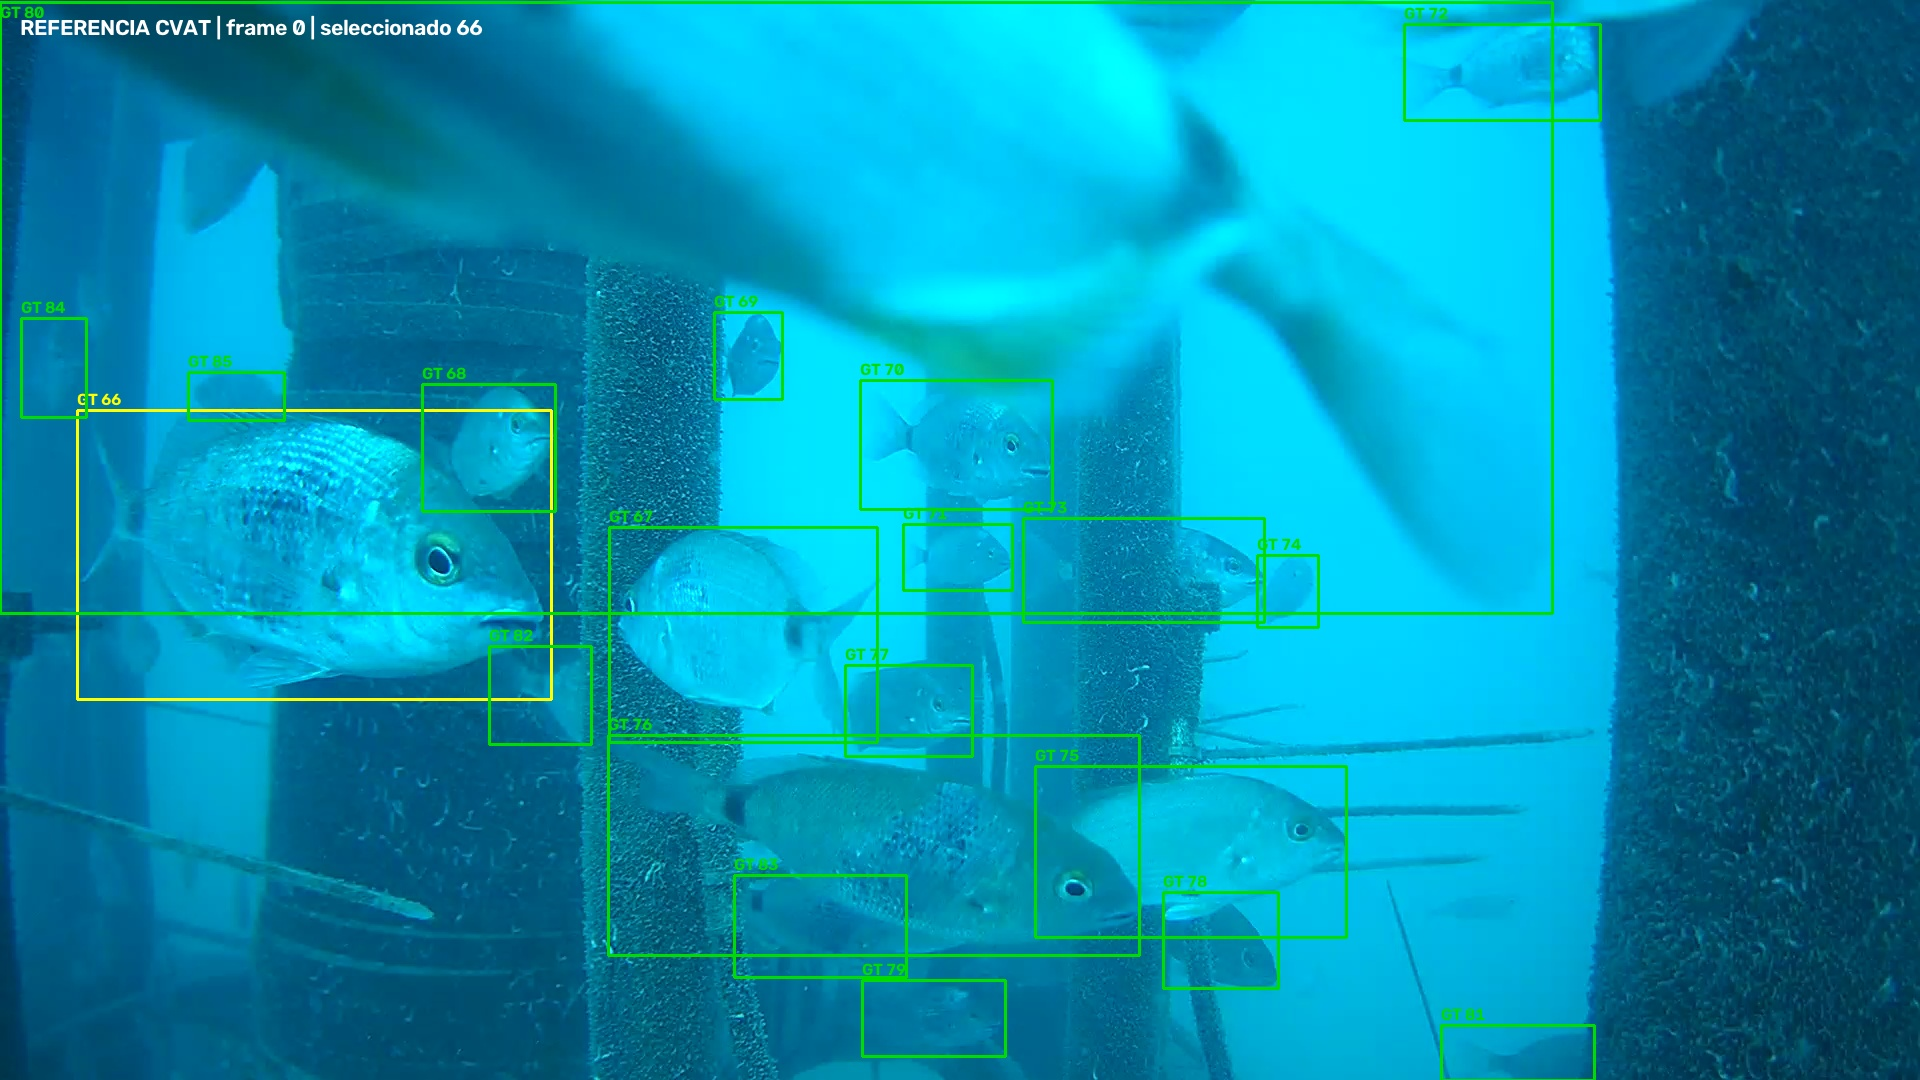

reference_frame_0600.jpg


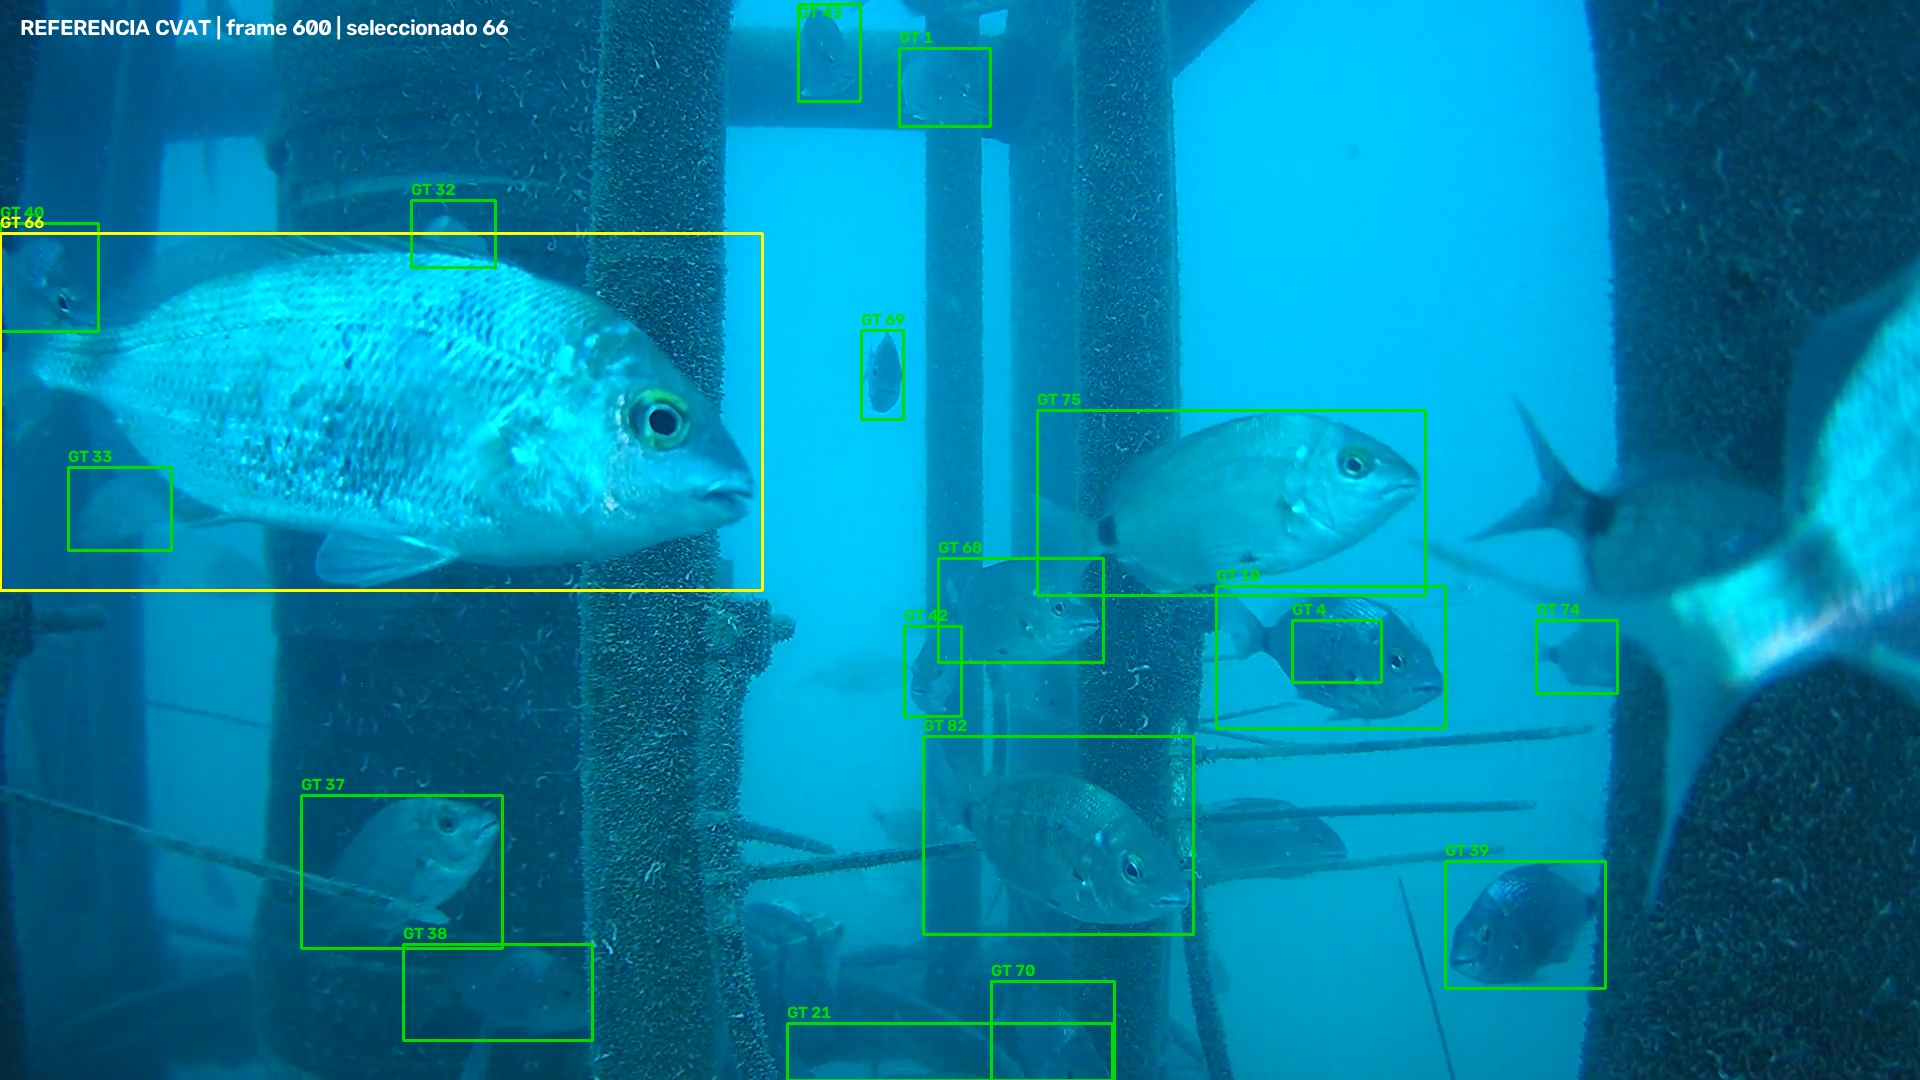

reference_frame_1199.jpg


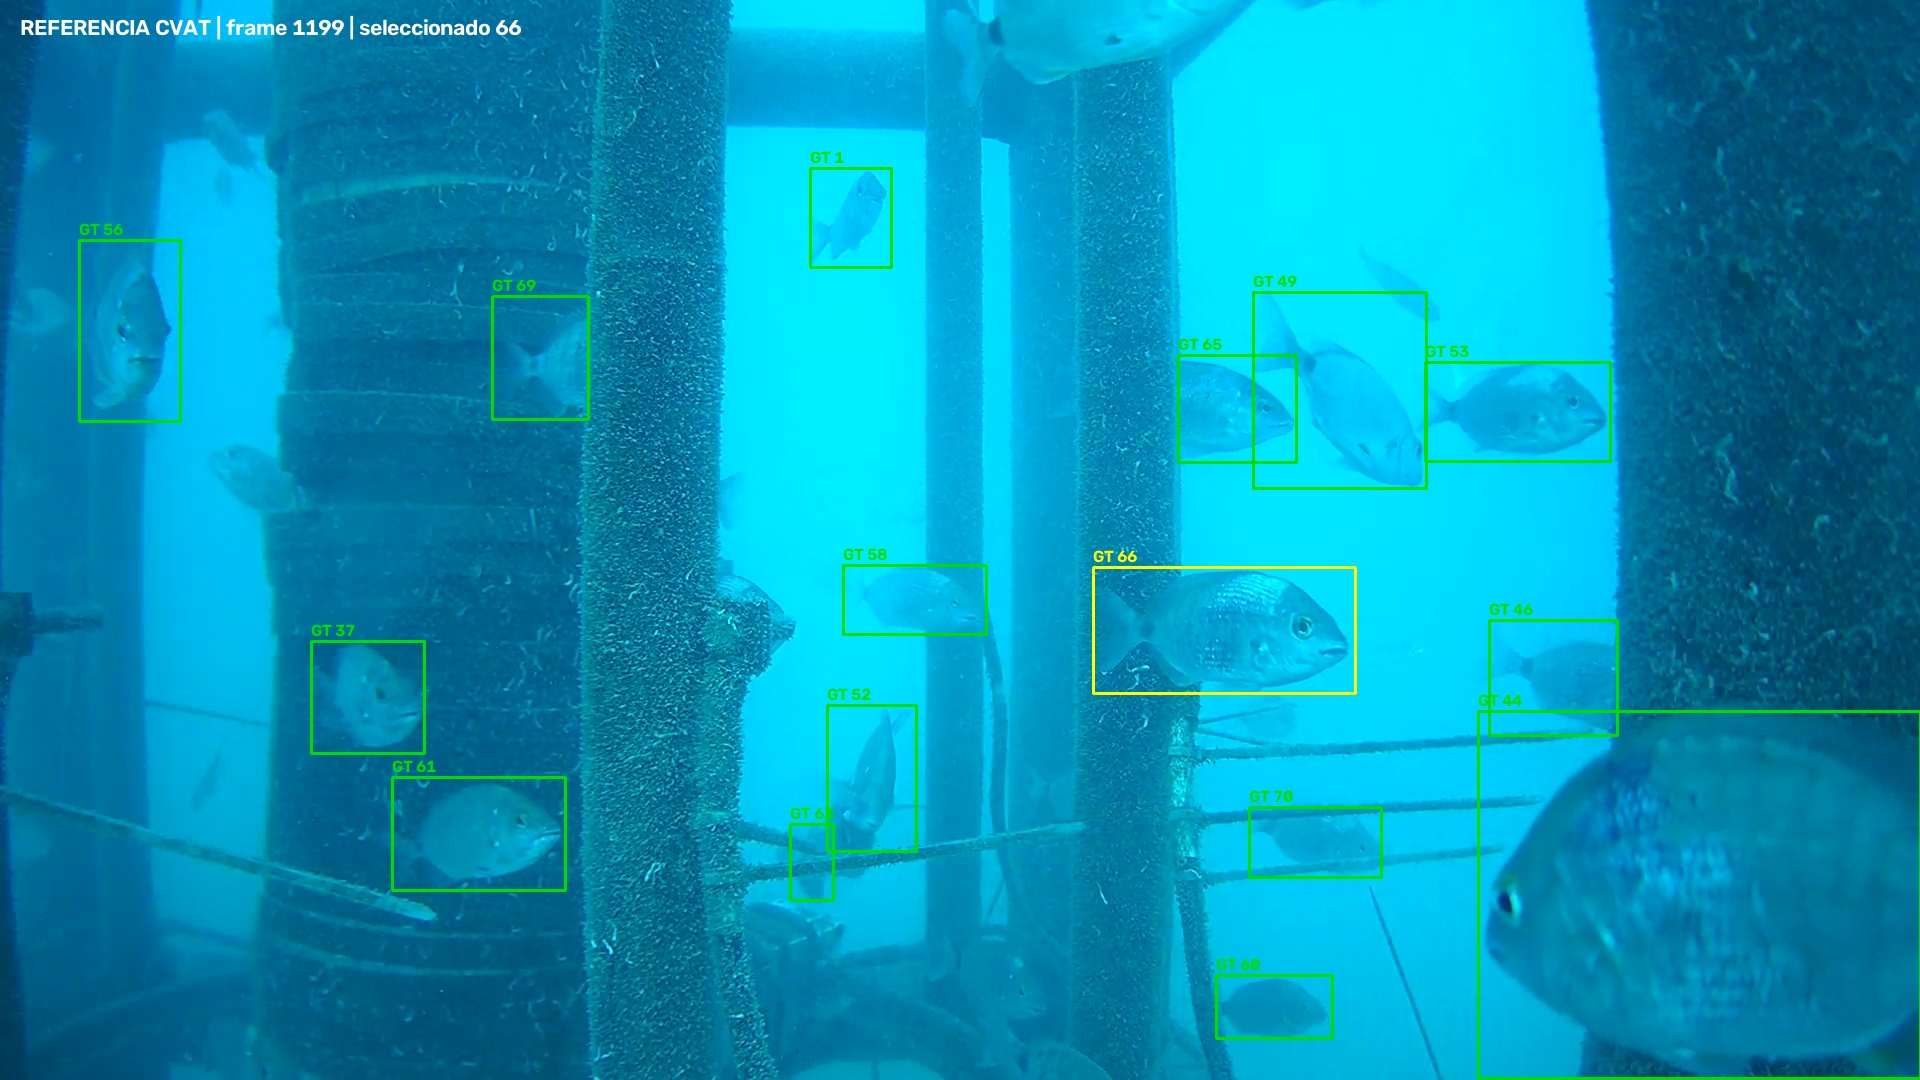

In [6]:
from IPython.display import display, Image, Markdown
for path in sorted(OUTPUT_DIR.glob('reference_frame_*.jpg')):
    print(path.name)
    display(Image(filename=str(path), width=950))


## 7 Señales y rapidez antes y después del FIR

El origen de imagen está arriba a la izquierda; x crece hacia la derecha e y
hacia abajo. Las distancias y velocidades son aparentes en píxeles. Las curvas
filtradas se muestran con retardo compensado para la comparación offline.


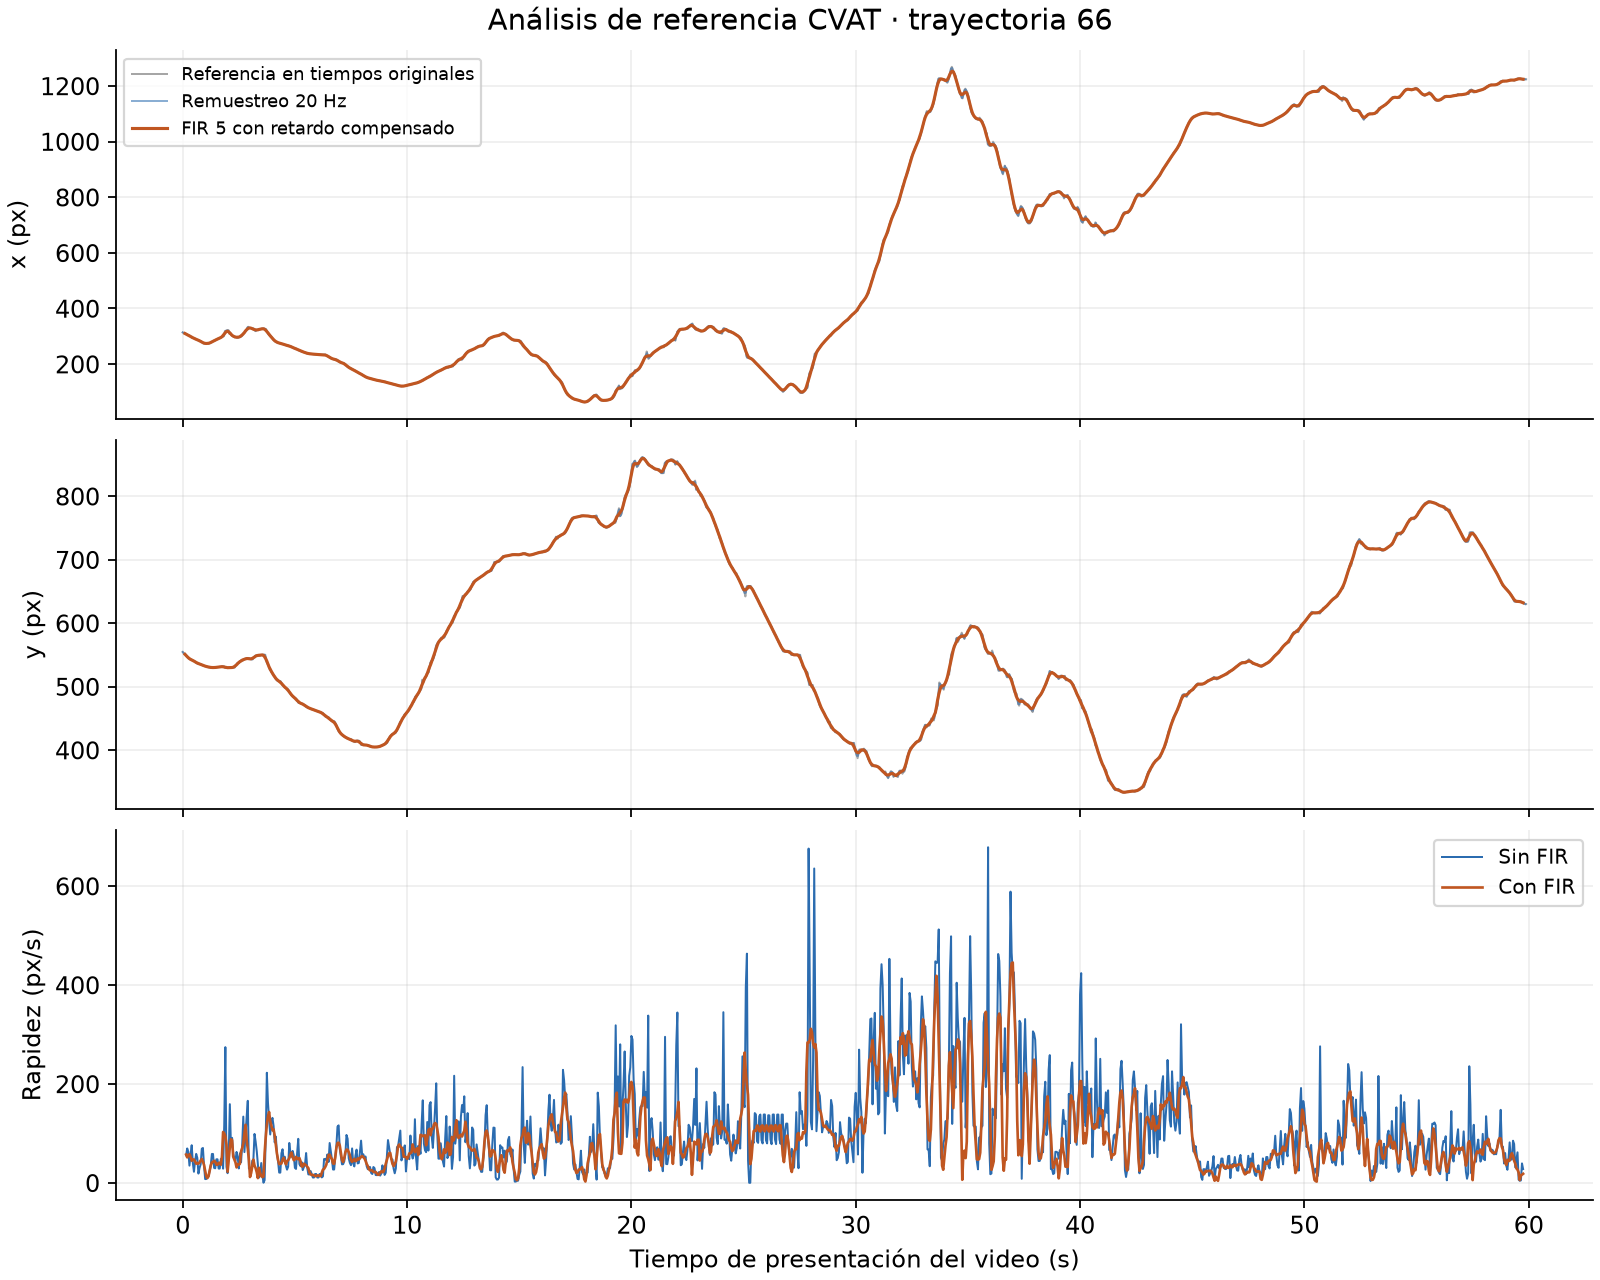

| Métrica | Sin FIR | Con FIR |
|---|---:|---:|
| path_length_px | 6380.1873 | 5534.0386 |
| net_displacement_px | 916.5738 | 917.7947 |
| mean_speed_px_s | 106.9604 | 92.7752 |
| max_speed_px_s | 678.4244 | 445.3956 |
| std_speed_px_s | 93.8138 | 72.0755 |
| duration_s | 59.6500 | 59.6500 |

Una reducción de rapidez o recorrido describe el suavizado; no prueba mayor exactitud.


In [7]:
display(Image(filename=str(OUTPUT_DIR / 'signals_and_speed.png'), width=1000))
import csv
rows = list(csv.reader((OUTPUT_DIR / 'metrics.csv').open(encoding='utf-8')))
table = '| Métrica | Sin FIR | Con FIR |\n|---|---:|---:|\n'
table += '\n'.join(f'| {r[0]} | {float(r[1]):.4f} | {float(r[2]):.4f} |' for r in rows[1:])
display(Markdown(table))
print('Una reducción de rapidez o recorrido describe el suavizado; no prueba mayor exactitud.')


## 8 Espectros y respuesta del filtro

El espectro representa posiciones anotadas y remuestreadas, con tendencia
lineal eliminada. La resolución de los bins es fs/N y el límite numérico de
Nyquist es fs/2. Los picos no demuestran por sí solos periodicidad biológica,
estrés, salud o alimentación. La frecuencia más alta interpretable depende
también de la captura original y de las anotaciones interpoladas.


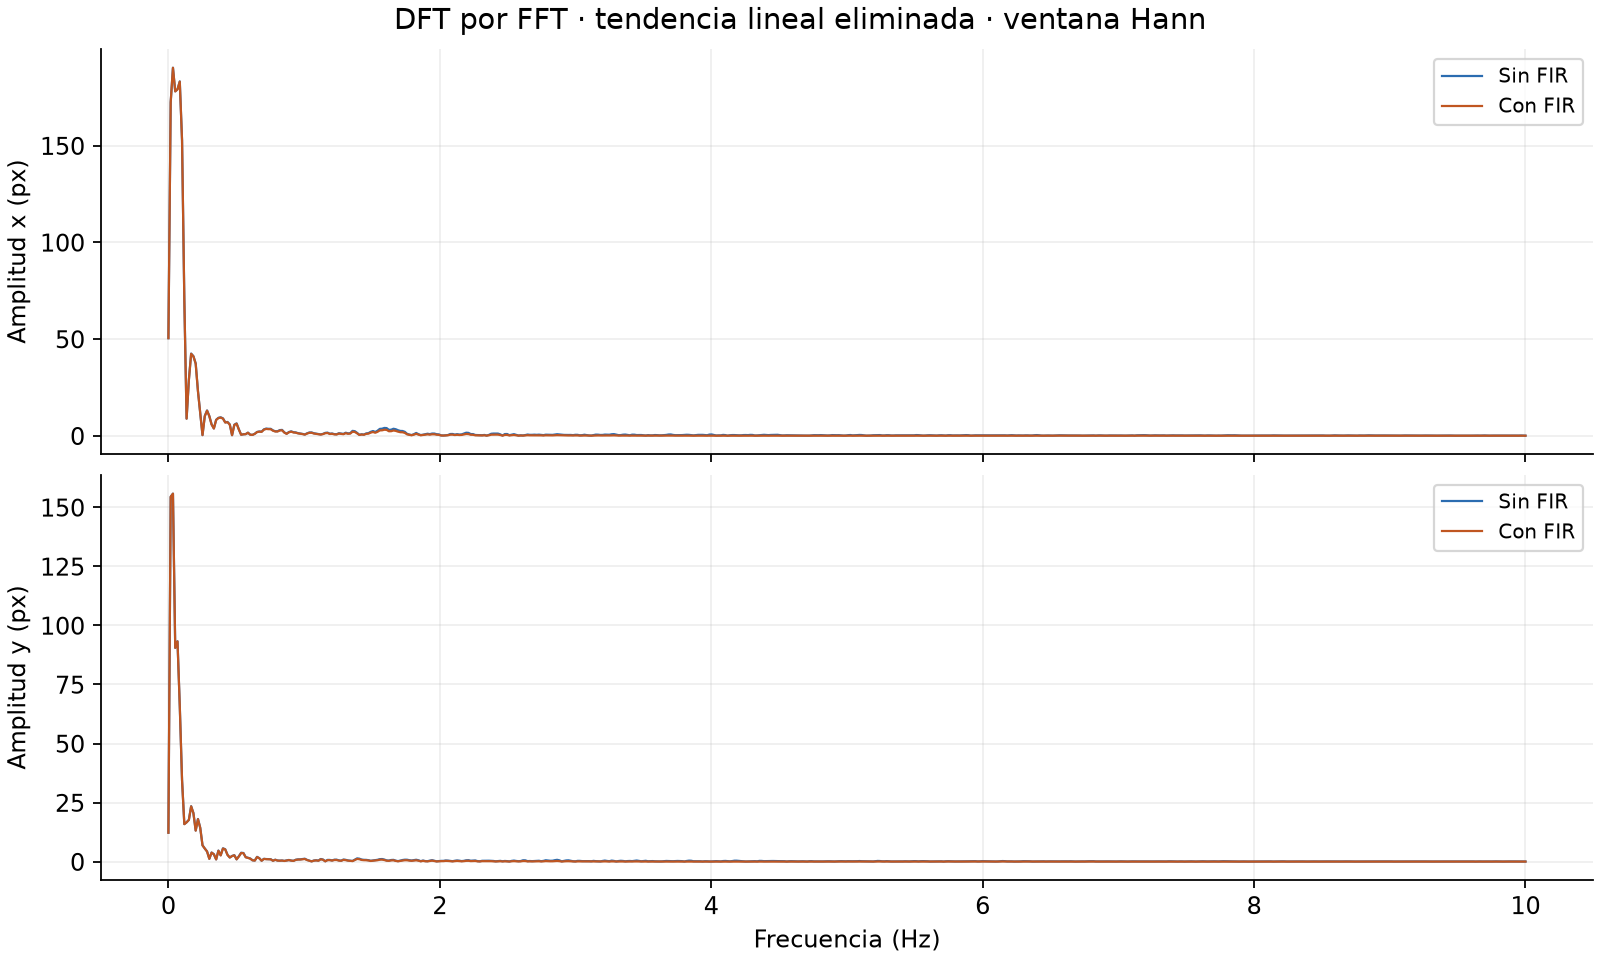

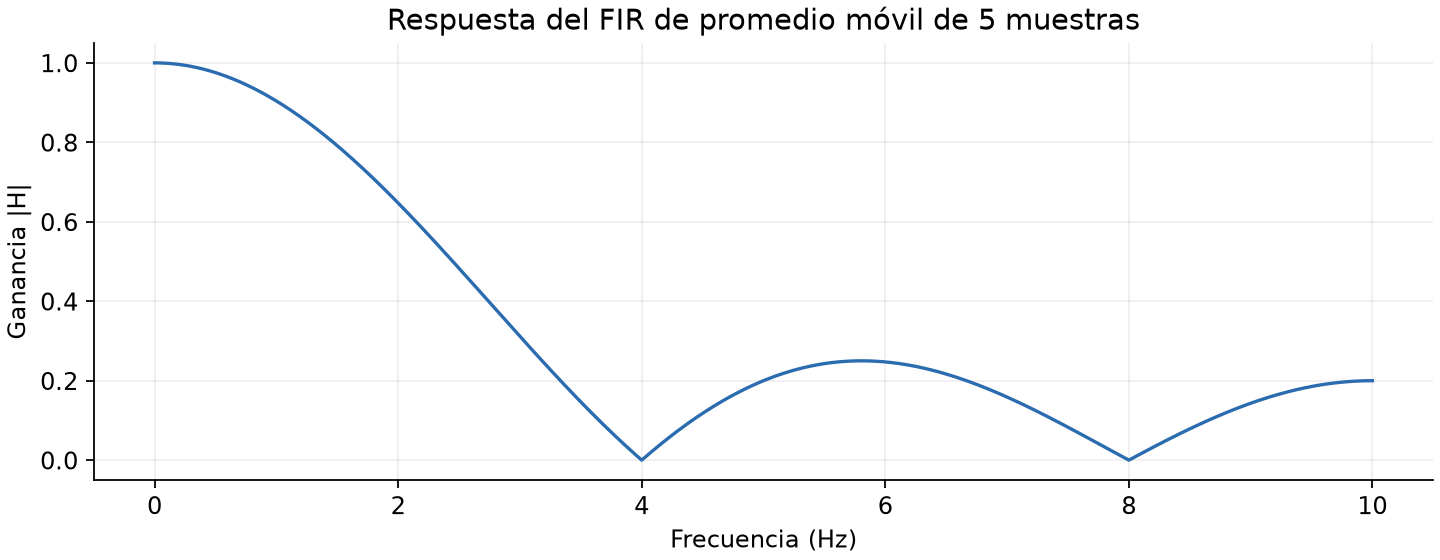

Resolución FFT (Hz): 0.01675041876046901
Retardo FIR (s): 0.1


In [8]:
display(Image(filename=str(OUTPUT_DIR / 'spectra.png'), width=1000))
display(Image(filename=str(OUTPUT_DIR / 'fir_response.png'), width=900))
print('Resolución FFT (Hz):', report['fft']['frequency_bin_hz'])
print('Retardo FIR (s):', report['fir']['delay_s'])


## 9 Exportación y límites del avance

Se generan coordenadas de referencia por pez, señales uniformes y filtradas,
rapidez, métricas, espectros, figuras y un JSON con parámetros, versiones y hashes
SHA-256 de los archivos de entrada. El ZIP permite conservar los resultados
antes de terminar la sesión de Colab.

**Pendiente:** detector, seguimiento automático, calibración de tamaño, umbrales
de actividad y evaluación independiente. No existen etiquetas de actividad o
tamaño que permitan reportar exactitud de esas clasificaciones en este avance.
**OBSEA se rechaza** si se intenta analizar porque su MP4 tiene 148 fotogramas
y su XML declara 150. Se requiere resolver esa correspondencia.

**Fuentes:**
- DIGI4ECO, [dataset y cita](https://doi.org/10.5281/zenodo.20701225), licencia
  CC BY 4.0 según el README de la descarga; conservar la atribución al compartir.
- NumPy, [convolución](https://numpy.org/doc/stable/reference/generated/numpy.convolve.html)
  y [DFT para datos reales](https://numpy.org/doc/stable/reference/generated/numpy.fft.rfft.html).
- Google, [preguntas frecuentes de Colab](https://research.google.com/colaboratory/faq.html).


In [9]:
import shutil
archive_path = shutil.make_archive(str(OUTPUT_DIR.parent / 'resultados_avance_56'), 'zip', OUTPUT_DIR)
print('Resultados guardados:', archive_path)
if IN_COLAB:
    from google.colab import files
    files.download(archive_path)


Resultados guardados: /Users/jmendivilv/Documents/PDS_PROYECTO/results/resultados_avance_56.zip
